# Introducción y Definición del Problema de Negocio

### Contexto y Problema de Negocio
* **Empresa:** Agencia de viajes y turismo digital.
* **Problema:** La plataforma recibe miles de fotografías subidas por usuarios y sitios asociados sin etiquetar. La clasificación manual es inviable en costo y tiempo, impidiendo personalizar la oferta turística en tiempo real.
* **Solución propuesta:** Sistema automatizado de visión computacional mediante una red convolucional (CNN) que clasifique las imágenes en tres entornos clave: **Ciudad**, **Mar** y **Naturaleza**, permitiendo perfilar preferencias y recomendar panoramas acordes al usuario.


### Objetivos del Proyecto
* **Objetivo General:** Desarrollar e implementar un modelo de clasificación multiclase basado en una Red Neuronal Convolucional (CNN) para categorizar imágenes de destinos turísticos con un flujo de trabajo reproducible.
* **Objetivos Específicos:**
  1. Preprocesar y adaptar imágenes RGB (150x150 px) al formato requerido por la CNN.
  2. Entrenar y validar la red neuronal monitoreando convergencia y sobreajuste (loss/accuracy).
  3. Evaluar el desempeño mediante métricas de clasificación (Accuracy, Precision, Recall, F1-Score y Matriz de Confusión).
  4. Analizar casos de error y explicar por que erró.


### Definición de KPIs
* **KPIs de Negocio:**
  * **Tiempo de catalogación:** Reducción del 95% en el tiempo de etiquetado frente al proceso manual.
  * **Tasa de cobertura de recomendación:** Clasificar al menos el 80% de las fotos entrantes sin intervención humana.
* **KPIs Técnicos (Modelo):**
  * **Accuracy global:** $\ge 85\%$ en el conjunto de prueba.
  * **Macro F1-Score:** $\ge 0.85$.


### Dataset y Justificación de la Variante
* **Fuente:** *Intel Image Classification Dataset*.
* **Variante del grupo:**
  * **Subconjunto de 3 clases:** `ciudad` (Street/Buildings), `mar` (Sea) y `naturaleza` (Forest/Mountain/Glacier). Justificado en los 3 pilares de destino del negocio turístico.
  * **Resolución:** $150 \times 150$ píxeles en 3 canales (RGB).
  * **Semilla fija:** `SEED = 42` para garantizar trazabilidad y reproducibilidad.
  * **Partición de datos:** `seg_train`(80% entrenamiento, 20% validación) 14000 img aprox. y `seg_test` test independiente 3000 img aprox.

### ¿Por que resulta pertinente comparar un mlp con una cnn?
  Comparar ambos modelos ilustra por qué las CNN son superiores para procesar imágenes. Mientras el MLP destruye la estructura espacial al aplanar los datos y sufre de una cantidad ineficiente de parámetros, la CNN preserva la geometría original y utiliza filtros compartidos para reconocer patrones visuales en cualquier posición, las cnn son mas costosas en cuanto a procesamiento pero son mas eficientes en el costo en memoria.

# 0. Extraccion de archivo zip

In [ ]:
#desde colab, subir el zip y descomentar esto, si es local hay que descomprimir
#hay que cambiar el nombre del archivo, espacios por guiones
#!unzip -q /content/Intel_Image_Classification.zip -d /content/dataset/

# 1. Particion de datos (Train, Validation, Test)

In [ ]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split
#cambiar las rutas segun donde este el dataset, estas estan para colab
# 1. Cargar Train Original y Test
ruta_train_orig = Path('/content/dataset/seg_train/seg_train')
train_orig_df = pd.DataFrame([{'ruta': str(img), 'etiqueta': img.parent.name} for img in ruta_train_orig.rglob('*.jpg')])

ruta_test = Path('/content/dataset/seg_test/seg_test')
test_df = pd.DataFrame([{'ruta': str(img), 'etiqueta': img.parent.name} for img in ruta_test.rglob('*.jpg')])

# 2. Particionar Train Original (80% Entrenamiento, 20% Validación)
train_df, val_df = train_test_split(
    train_orig_df,
    test_size=0.20,
    random_state=42,
    stratify=train_orig_df['etiqueta'] # Mantiene la proporción de clases equilibrada
)

train_df = train_df.copy()
val_df = val_df.copy()

mapeo_clases = {
    'buildings': 'ciudad',
    'street': 'ciudad',
    'sea': 'mar',
    'forest': 'naturaleza',
    'glacier': 'naturaleza',
    'mountain': 'naturaleza'
}

# Reemplazar las etiquetas originales en los 3 splits
train_df['etiqueta'] = train_df['etiqueta'].replace(mapeo_clases)
val_df['etiqueta'] = val_df['etiqueta'].replace(mapeo_clases)
test_df['etiqueta'] = test_df['etiqueta'].replace(mapeo_clases)

El dataset tiene 3 carpetas, train, test y pred, como pred no esta etiquetada y test no es muy grande, se decidio partir train en 80/20 para train y validacion mientras que test se conservo para test.

Por requisito del caso, el dataset se reorganizo en 3 clases, naturaleza (Forest/Mountain/Glacier), ciudad (Street/Buildings) y mar (sea)

# 2. EDA

/tmp/ipykernel_2755/2350040942.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=train_df, x='etiqueta', order=train_df['etiqueta'].value_counts().index, palette='viridis')


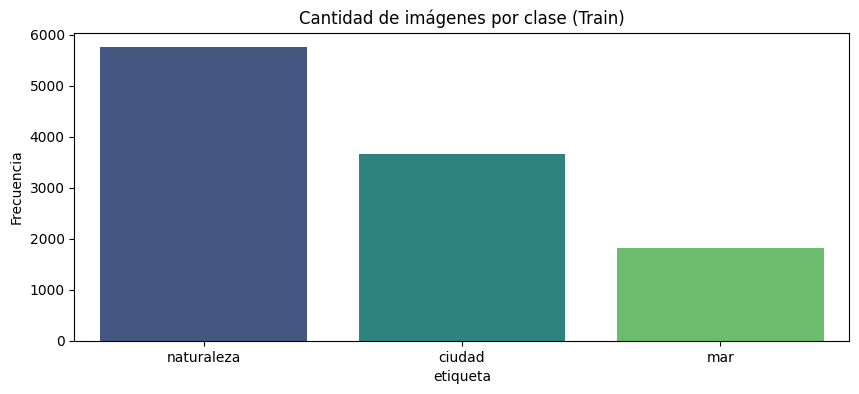

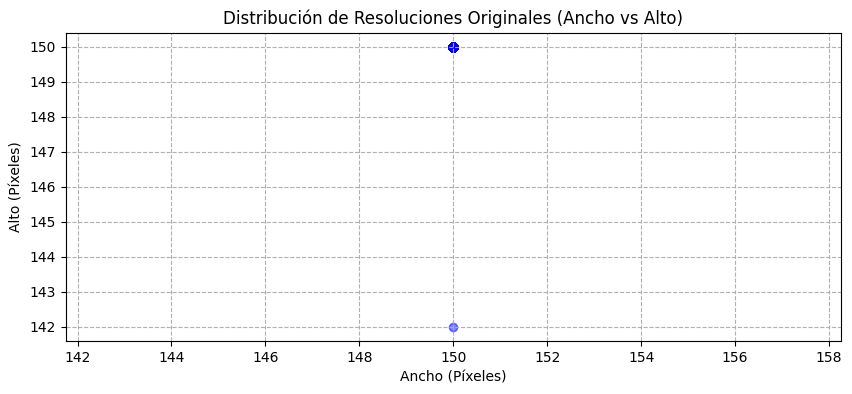

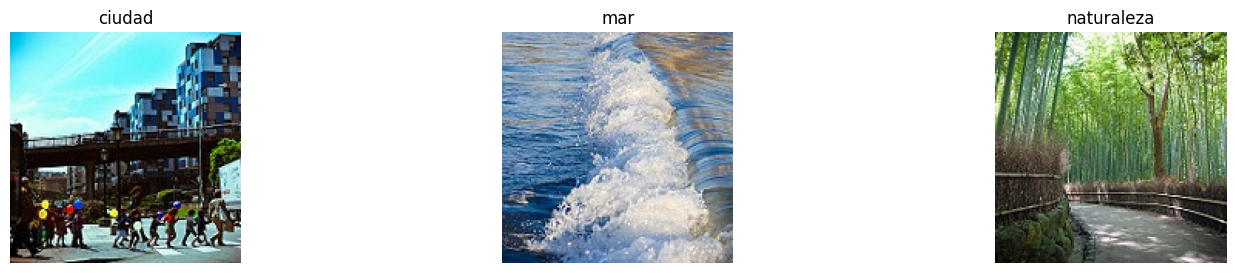

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import numpy as np

# 1. Distribución de clases: Para verificar desbalance
plt.figure(figsize=(10, 4))
sns.countplot(data=train_df, x='etiqueta', order=train_df['etiqueta'].value_counts().index, palette='viridis')
plt.title('Cantidad de imágenes por clase (Train)')
plt.ylabel('Frecuencia')
plt.show()

# 2. Análisis de dimensiones: Verificar resoluciones originales
# Se usa un muestreo (ej. 500) para no saturar la RAM ni demorar excesivamente
muestreo = train_df.sample(500, random_state=42)
anchos, altos = [], []

for ruta in muestreo['ruta']:
    with Image.open(ruta) as img:
        ancho, alto = img.size
        anchos.append(ancho)
        altos.append(alto)

plt.figure(figsize=(10, 4))
plt.scatter(anchos, altos, alpha=0.5, color='blue')
plt.title('Distribución de Resoluciones Originales (Ancho vs Alto)')
plt.xlabel('Ancho (Píxeles)')
plt.ylabel('Alto (Píxeles)')
plt.grid(True, linestyle='--')
plt.show()

# 3. Visualización: Mostrar 1 ejemplo aleatorio por clase
clases = train_df['etiqueta'].unique()
fig, axes = plt.subplots(1, len(clases), figsize=(18, 3))

for ax, clase in zip(axes, clases):
    ruta_img = train_df[train_df['etiqueta'] == clase].sample(1, random_state=42).iloc[0]['ruta']
    img = Image.open(ruta_img)
    ax.imshow(img)
    ax.set_title(clase)
    ax.axis('off')
plt.show()

El conjunto de datos consta de imágenes de 150x150px distribuidas en tres clases principales que presentan un claro desequilibrio. Este desbalance surge al agrupar las categorías originales (que sí estaban balanceadas): la clase "naturaleza" ahora contiene tres subcategorías (mountain, glacier, forest), "ciudad" incluye dos (building, street), y "mar" abarca solo una (sea). Por lo tanto, será necesario aplicar técnicas para corregir esta disparidad.

# 3. Preprocesamiento

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# 1. Parámetros generales
TAMANO_IMG = (150,150)
BATCH_SIZE = 32
#Data augmentation
datagen_train = ImageDataGenerator(
    rescale=1./255,
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)
# 2. Crear el Generador (Preprocesamiento)
datagen = ImageDataGenerator(rescale=1./255)

# 3. Conectar los DataFrames
train_gen = datagen_train.flow_from_dataframe(
    dataframe=train_df,
    x_col='ruta',
    y_col='etiqueta',
    target_size=TAMANO_IMG,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

val_gen = datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col='ruta',
    y_col='etiqueta',
    target_size=TAMANO_IMG,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

test_gen = datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col='ruta',
    y_col='etiqueta',
    target_size=TAMANO_IMG,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

Found 11227 validated image filenames belonging to 3 classes.
Found 2807 validated image filenames belonging to 3 classes.
Found 3000 validated image filenames belonging to 3 classes.


Se mantuvo la dimension original porque las cnn se benefician de los bordes, se redimensiona a 150x150 en caso de que haya imagenes con otras dimensiones.

Se configuraron dos generadores de datos (datagen). El primero, exclusivo para el conjunto de entrenamiento, aplica data augmentation. El segundo, destinado a validación y prueba, únicamente realiza un reescalado de los píxeles. El aumento de datos se restringe al entrenamiento porque aplicarlo en las fases de evaluación invalidaría las pruebas, el modelo evaluaría imágenes artificialmente similares, lo que inflaría engañosamente las métricas de rendimiento. Por esta razón, es fundamental realizar la partición de los datos antes de aplicar estas transformaciones.

Se eligio un batch size de 32 por ser un estándar altamente efectivo que ofrece el mejor equilibrio entre rendimiento computacional y calidad de aprendizaje (debe ser una potencia de 2 para optimizar el procesamiento de la vram).

# 4. Creación de la arquitectura del modelo


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense, Conv2D, MaxPooling2D, Dropout

NUM_CLASES = len(train_gen.class_indices) # Detecta cantidad de clases automáticamente
INPUT_SHAPE = (150, 150, 3)

# CNN
modelo_cnn = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=INPUT_SHAPE),
    MaxPooling2D(2,2),
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),
    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(2,2),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(NUM_CLASES, activation='softmax')
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


MaxPooling reduce a la mitad el ancho y el alto del mapa de características de entrada tomando el valor máximo de cada bloque de 2 × 2 píxeles, esto reduce la cantidad de datos y calculo, conserva solo lo mas importante al elegir el valor máximo (se queda con la caracterisica mas prominente de cada zona) y ayuda a que reconozca un objeto aunque se desplace.

Se implementaron 3 capas convolucionales, por lo anterior, se duplica el numero de filtros por cada bloque para no perder caracteristicas, esto hace que pase de ver la geometria a ver "que es", todas las capas tienen un tamaño de filtro de 3x3 por ser el estandar.

Se hace un dropout fuerte (0.5) antes de la capa softmax para evitar el sobreajuste, es la transicion entre la extraccion de caracteristicas visuales y la clasificacion final

Se uso ReLu porque es computacionalmente eficiente y mitiga el problema de desvanecimiento de gradiente, permitiendo que la red converja más rapido durante el entrenamiento. Se uso softmax porque es obligatoria para la clasificacion multiclase

Compilación y Entrenamiento

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
# Compilar el modelo
modelo_cnn.compile(
    optimizer='adam',
    loss='categorical_crossentropy', # Obligatorio para class_mode='categorical'
    metrics=['accuracy']
)

# Calcular pesos automáticos basados en las frecuencias reales
etiquetas_reales = train_gen.classes
clases_unicas = np.unique(etiquetas_reales)

pesos_calculados = compute_class_weight(
    class_weight='balanced',
    classes=clases_unicas,
    y=etiquetas_reales
)

pesos_clases = dict(zip(clases_unicas, pesos_calculados))

historial = modelo_cnn.fit(
    train_gen,
    validation_data=val_gen,
    epochs=30,
    class_weight=pesos_clases
)

Epoch 1/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 89s 229ms/step - accuracy: 0.5965 - loss: 0.7780 - val_accuracy: 0.6633 - val_loss: 0.7241
Epoch 2/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 73s 207ms/step - accuracy: 0.7567 - loss: 0.5626 - val_accuracy: 0.7485 - val_loss: 0.5368
Epoch 3/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 75s 213ms/step - accuracy: 0.8060 - loss: 0.4573 - val_accuracy: 0.8942 - val_loss: 0.3097
Epoch 4/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 70s 199ms/step - accuracy: 0.8365 - loss: 0.4110 - val_accuracy: 0.7902 - val_loss: 0.5000
Epoch 5/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 72s 206ms/step - accuracy: 0.8589 - loss: 0.3565 - val_accuracy: 0.8899 - val_loss: 0.3028
Epoch 6/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 71s 203ms/step - accuracy: 0.8667 - loss: 0.3399 - val_accuracy: 0.8678 - val_loss: 0.3747
Epoch 7/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 71s 202ms/step - accuracy: 0.8759 - loss: 0.3240 - val_accuracy: 0.9206 - val_loss: 0.2099
Epoch 8/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 81s 200ms/step - accuracy: 0.8844 - loss: 0

Adam ajusta dinámicamente la tasa de aprendizaje (learning rate) durante el entrenamiento. Es más rápido y robusto frente a mínimos locales que el descenso de gradiente estocástico (SGD) tradicional

categorical_crossentropy es la función de pérdida matemática estándar y más eficiente para medir el error en problemas de clasificación de más de dos clases.

Metricas de entrenamiento

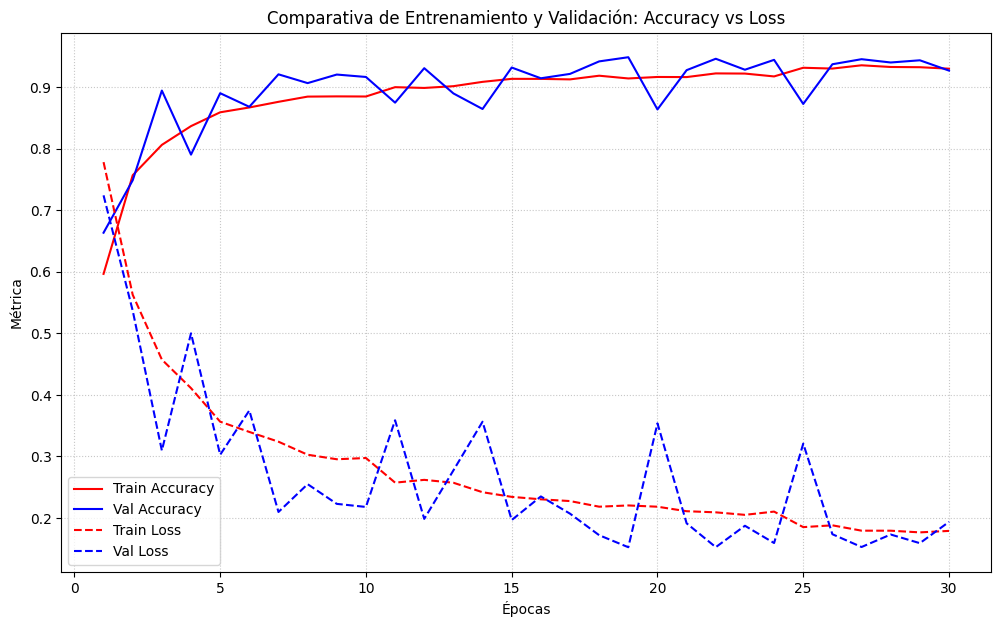

In [ ]:
import matplotlib.pyplot as plt

# Extraer métricas de entrenamiento y validación
acc = historial.history['accuracy']
loss = historial.history['loss']
val_acc = historial.history['val_accuracy']
val_loss = historial.history['val_loss']

epocas = range(1, len(acc) + 1)

plt.figure(figsize=(12, 7))

# rojo:train azul:val
plt.plot(epocas, acc, 'r-', label='Train Accuracy')
plt.plot(epocas, val_acc, 'b-', label='Val Accuracy')
plt.plot(epocas, loss, 'r--', label='Train Loss')
plt.plot(epocas, val_loss, 'b--', label='Val Loss')

plt.title('Comparativa de Entrenamiento y Validación: Accuracy vs Loss')
plt.xlabel('Épocas')
plt.ylabel('Métrica')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.7)
plt.show()

Interpretación del gráfico (diagnóstico del entrenamiento):

Ambas curvas de Train y Validation mejoran juntas (Loss baja, Accuracy sube) y se estabilizan cerca una de la otra, no sufrio subajuste o sobreajuste importante.


# 5. Evaluación y Predicciones

In [ ]:
from sklearn.metrics import classification_report
import numpy as np

# 1. Generar predicciones del set de prueba (importante: test_gen debe tener shuffle=False)
predicciones = modelo_cnn.predict(test_gen)
clases_predichas = np.argmax(predicciones, axis=1) # Convierte array de probabilidades al índice mayor (ej. [0.1, 0.8, 0.1] -> 1)

# 2. Extraer las etiquetas reales numéricas
clases_reales = test_gen.classes

# 3. Generar y mostrar el reporte
nombres_clases = list(test_gen.class_indices.keys())
print(classification_report(clases_reales, clases_predichas, target_names=nombres_clases))

94/94 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step
              precision    recall  f1-score   support

      ciudad       0.95      0.97      0.96       938
         mar       0.75      0.96      0.85       510
  naturaleza       0.99      0.88      0.93      1552

    accuracy                           0.92      3000
   macro avg       0.90      0.94      0.91      3000
weighted avg       0.94      0.92      0.93      3000



94/94 ━━━━━━━━━━━━━━━━━━━━ 4s 39ms/step


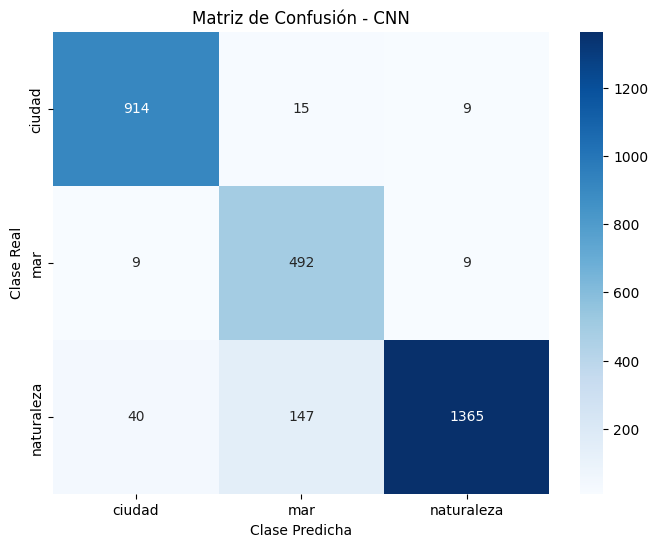

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import numpy as np

# 1. CAMBIAR: 'modelo_cnn' por el modelo que desees evaluar (ej. 'modelo_mlp')
# Nota: test_gen debe ejecutarse completo sin alterar su orden (shuffle=False)
predicciones = modelo_cnn.predict(test_gen)
clases_predichas = np.argmax(predicciones, axis=1)
clases_reales = test_gen.classes

# 2. Generar la matriz
cm = confusion_matrix(clases_reales, clases_predichas)
nombres_clases = list(test_gen.class_indices.keys())

# 3. Graficar con Seaborn
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=nombres_clases, yticklabels=nombres_clases)

# CAMBIAR: El título si cambiaste de modelo
plt.title('Matriz de Confusión - CNN')
plt.ylabel('Clase Real')
plt.xlabel('Clase Predicha')
plt.show()

Las métricas muestran un modelo con un rendimiento general muy sólido, alcanzando una exactitud (accuracy) global del 92% sobre las 3000 imágenes evaluadas.

**A nivel de cada clase, se observa lo siguiente:**

**Ciudad:** Presenta un rendimiento excelente y equilibrado, con un F1-score de 0.96. Su recall de 0.98 indica que el modelo es capaz de encontrar exitosamente el 98% de todas las imágenes reales de ciudad.

**Naturaleza (Clase mayoritaria):** Destaca por una precisión casi perfecta de 0.99, lo que significa que cuando el modelo predice "naturaleza", acierta el 99% de las veces. Sin embargo, su recall cae a 0.88, indicando que se le escapan un 12% de imágenes de naturaleza real (falsos negativos) 49 en ciudad y 138 mar.

**Mar (Clase minoritaria):** Presenta un comportamiento opuesto a naturaleza. Tiene un buen recall (0.94), logrando encontrar casi todas las imágenes de mar, pero su precisión es la más baja del modelo con 0.76. Esto sugiere que el modelo tiene una tendencia a generar falsos positivos para esta clase, confunde y clasifica erróneamente algunas de las imágenes de la clase "naturaleza" como "mar" (138).

# 6. Errores

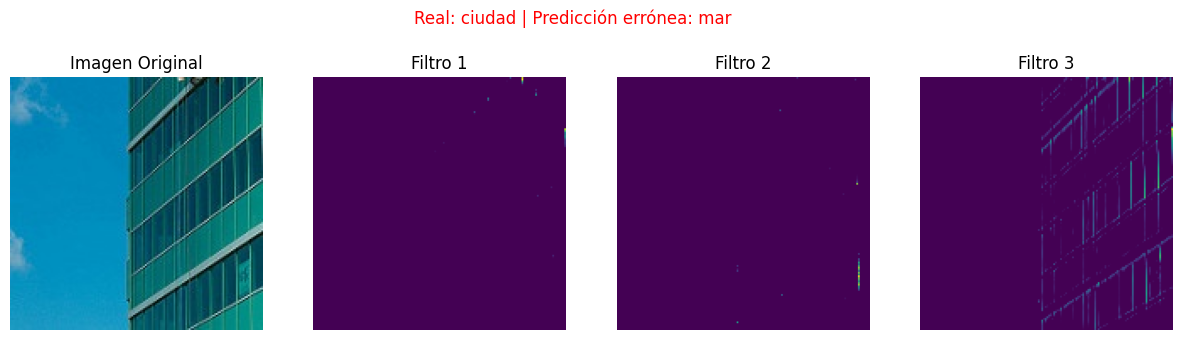

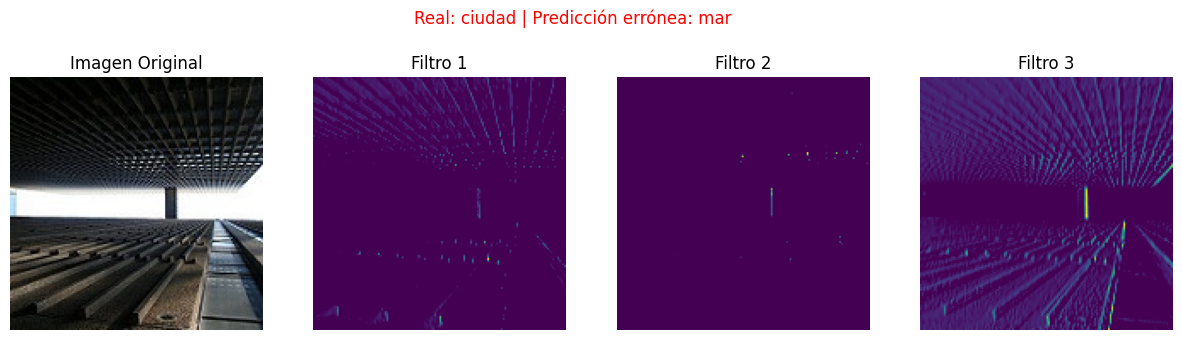

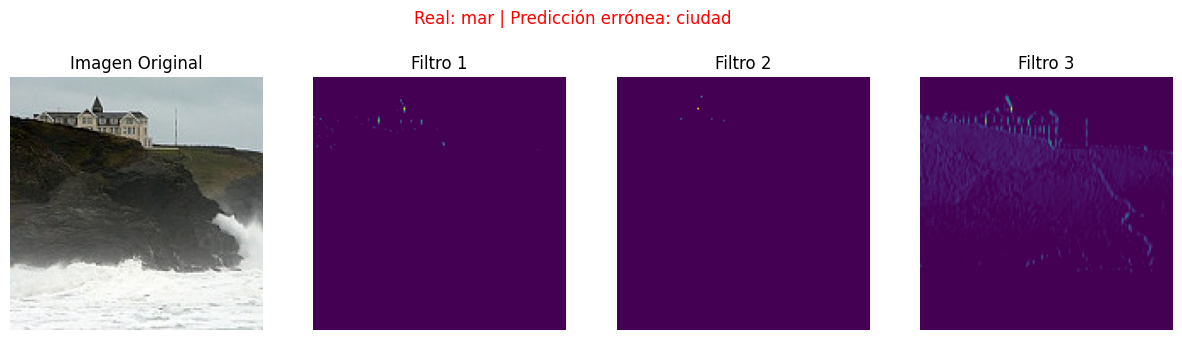

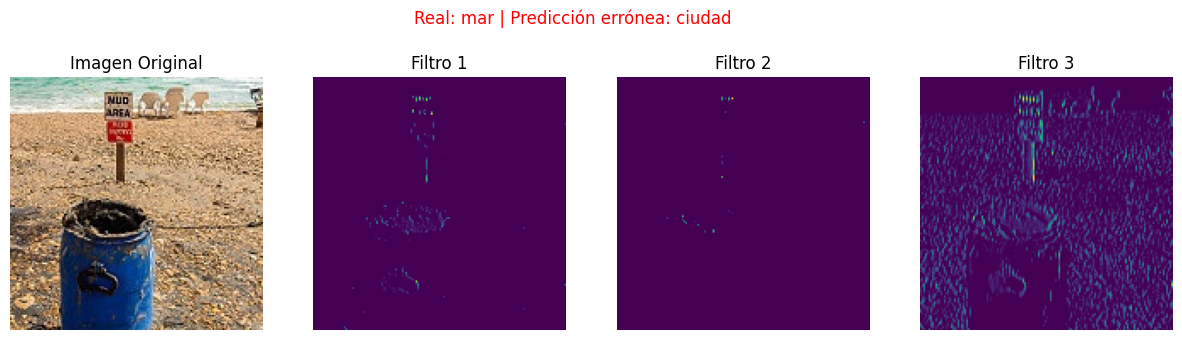

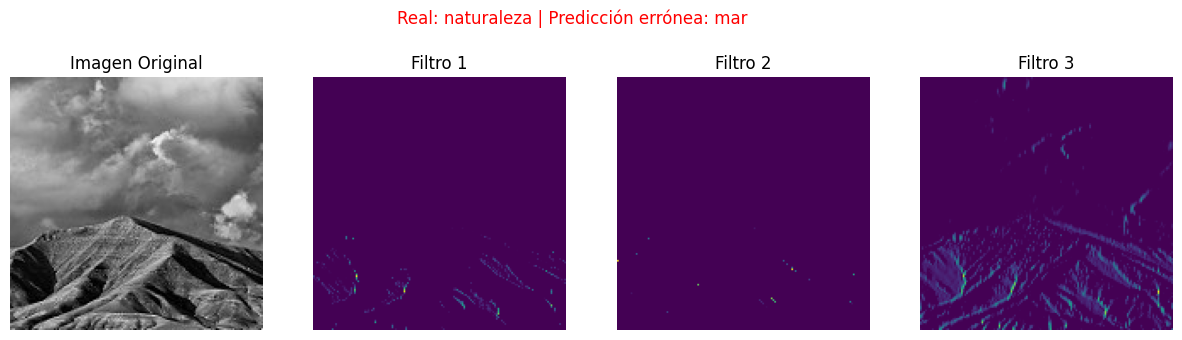

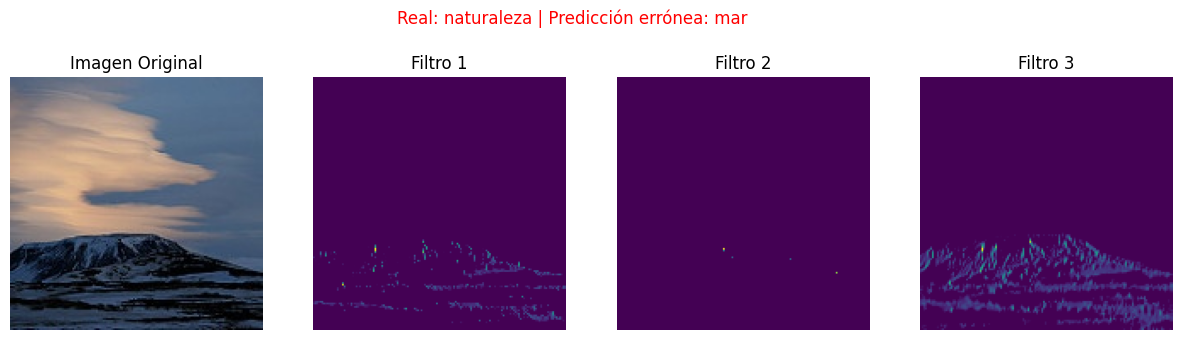

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt
import numpy as np

indices_errores = np.where(clases_reales != clases_predichas)[0]
errores_seleccionados = []

for clase in np.unique(clases_reales):
    errores_clase = [i for i in indices_errores if clases_reales[i] == clase]
    errores_seleccionados.extend(errores_clase[:2]) # Toma las primeras 2

# Si quieres ver la capa 0 usas: [modelo_cnn.layers[0]]
# Si quieres ver una capa más profunda (ej. capa 2), puedes usar: modelo_cnn.layers[:3]
modelo_filtros = tf.keras.Sequential([modelo_cnn.layers[0]])

nombres_clases = list(test_gen.class_indices.keys())

for idx in errores_seleccionados:
    ruta_img = test_gen.filepaths[idx]
    real = nombres_clases[clases_reales[idx]]
    predicha = nombres_clases[clases_predichas[idx]]

    tamano_correcto = test_gen.target_size

    img = image.load_img(ruta_img, target_size=tamano_correcto)
    img_tensor = image.img_to_array(img) / 255.0
    img_tensor = np.expand_dims(img_tensor, axis=0)

    activaciones = modelo_filtros.predict(img_tensor, verbose=0)

    fig, axes = plt.subplots(1, 4, figsize=(15, 4))
    fig.suptitle(f'Real: {real} | Predicción errónea: {predicha}', color='red')
    axes[0].imshow(img)
    axes[0].set_title('Imagen Original')
    axes[0].axis('off')
    num_filtros = min(3, activaciones.shape[-1])
    for i in range(num_filtros):
        # activaciones[0, :, :, i] extrae el mapa de la imagen 0, filtro i
        axes[i+1].imshow(activaciones[0, :, :, i], cmap='viridis')
        axes[i+1].set_title(f'Filtro {i+1}')
        axes[i+1].axis('off')

    plt.show()

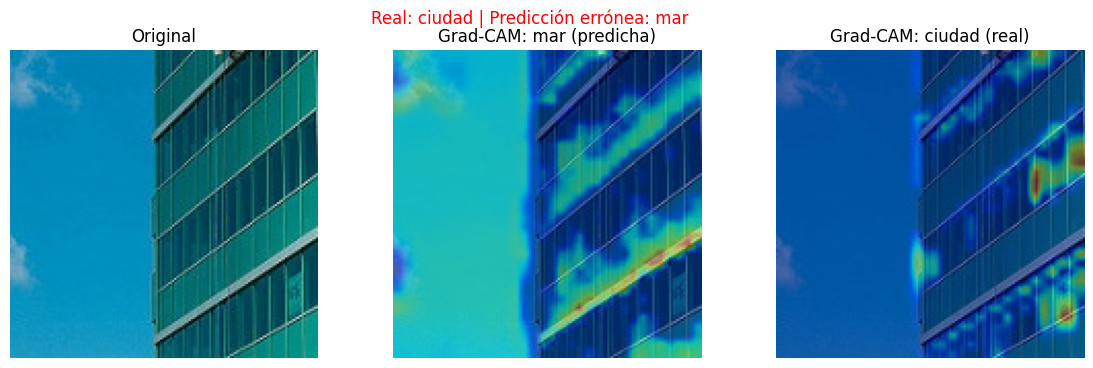

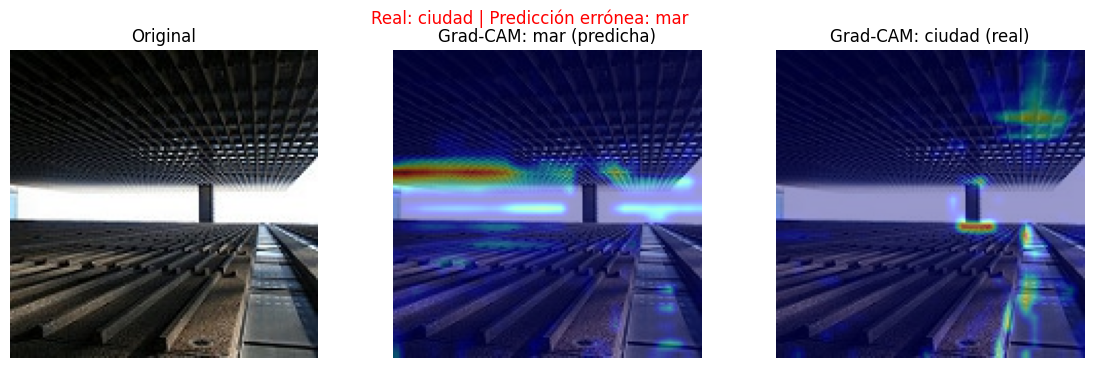

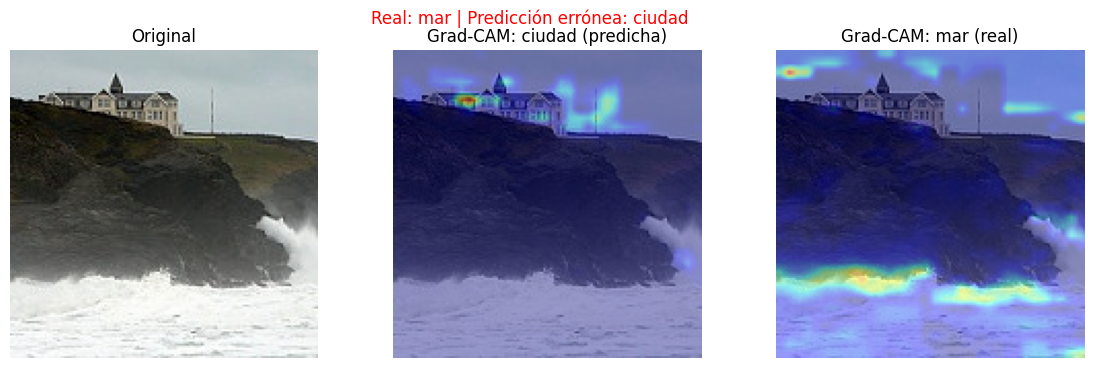

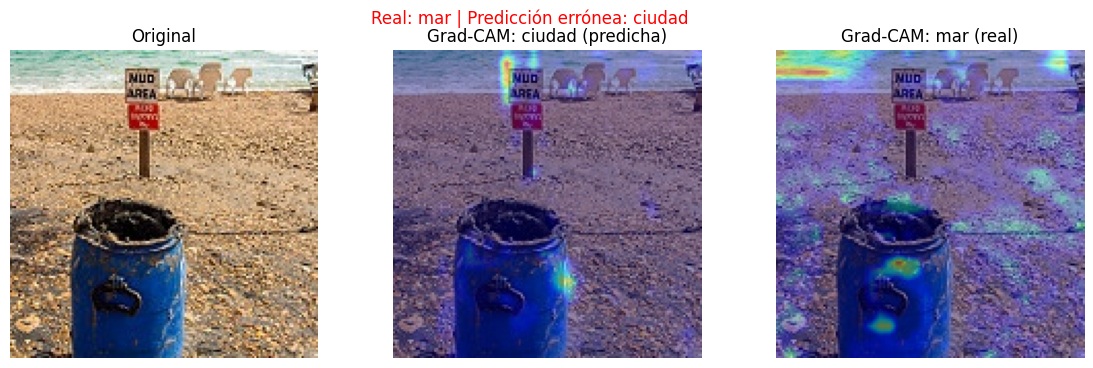

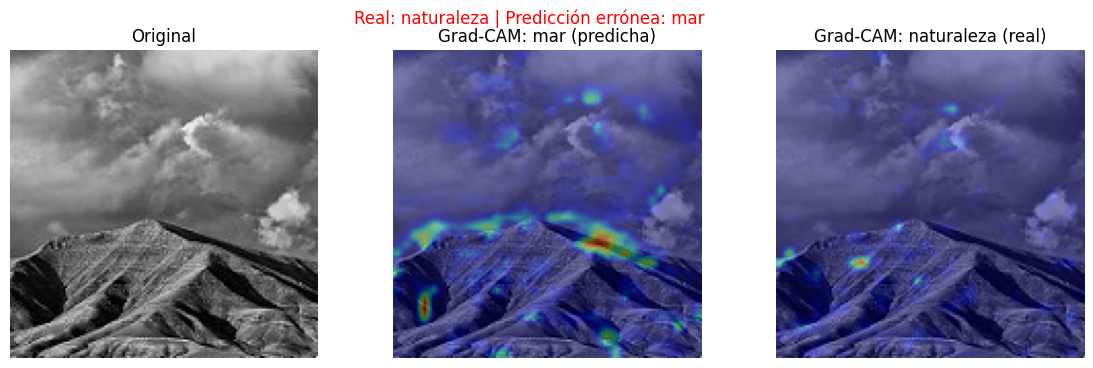

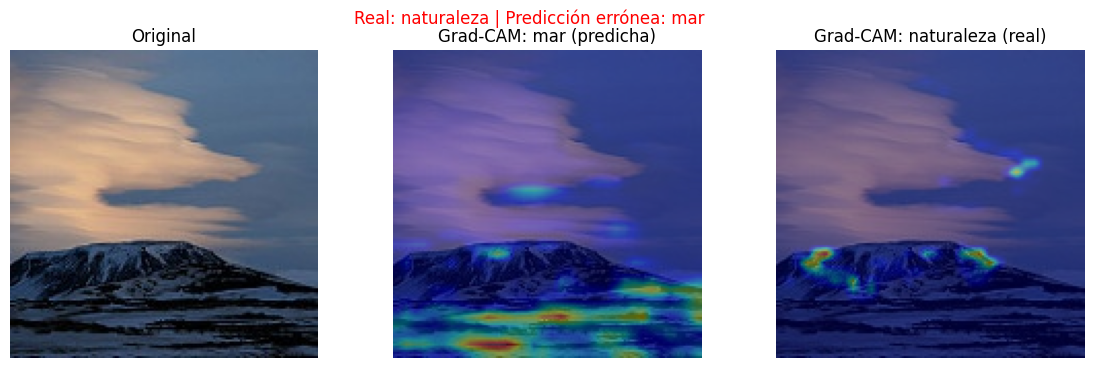

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.preprocessing import image

# Última capa convolucional (detectada automáticamente)
ultima_conv = [l for l in modelo_cnn.layers if isinstance(l, Conv2D)][-1].name

def calcular_gradcam(modelo, img_tensor, nombre_capa_conv, clase_idx=None):
    """
    img_tensor: array (1, H, W, 3) ya reescalado a [0,1]
    clase_idx: clase objetivo; si es None usa la clase predicha
    """
    x = tf.convert_to_tensor(img_tensor)
    with tf.GradientTape() as tape:
        for capa in modelo.layers:
            x = capa(x)
            if capa.name == nombre_capa_conv:
                mapas_conv = x          # activaciones de la capa conv
        predicciones = x                # salida final (softmax)
        if clase_idx is None:
            clase_idx = int(tf.argmax(predicciones[0]))
        puntaje = predicciones[:, clase_idx]

    # Gradiente del puntaje de la clase respecto a los mapas de activación
    grads = tape.gradient(puntaje, mapas_conv)
    pesos = tf.reduce_mean(grads, axis=(1, 2))               # (1, canales)
    heatmap = tf.reduce_sum(mapas_conv * pesos[:, None, None, :], axis=-1)[0]
    heatmap = tf.nn.relu(heatmap)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)      # normaliza a [0,1]
    return heatmap.numpy(), clase_idx


def superponer(img, heatmap, alpha=0.4):
    h, w = img.shape[:2]
    hm = tf.image.resize(heatmap[..., None], (h, w)).numpy().squeeze()
    hm_color = plt.cm.jet(hm)[..., :3]
    return np.clip((1 - alpha) * img + alpha * hm_color, 0, 1)


nombres_clases = list(test_gen.class_indices.keys())

for idx in errores_seleccionados:
    ruta_img = test_gen.filepaths[idx]
    real = nombres_clases[clases_reales[idx]]
    predicha = nombres_clases[clases_predichas[idx]]

    img = image.load_img(ruta_img, target_size=test_gen.target_size)
    img_arr = image.img_to_array(img) / 255.0
    img_tensor = np.expand_dims(img_arr, axis=0)

    # Grad-CAM de la clase predicha (por qué se equivocó)
    hm_pred, _ = calcular_gradcam(modelo_cnn, img_tensor, ultima_conv,
                                  clase_idx=clases_predichas[idx])
    # Grad-CAM de la clase real (qué debería haber mirado)
    hm_real, _ = calcular_gradcam(modelo_cnn, img_tensor, ultima_conv,
                                  clase_idx=clases_reales[idx])

    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    fig.suptitle(f'Real: {real} | Predicción errónea: {predicha}', color='red')
    axes[0].imshow(img_arr);                        axes[0].set_title('Original')
    axes[1].imshow(superponer(img_arr, hm_pred));   axes[1].set_title(f'Grad-CAM: {predicha} (predicha)')
    axes[2].imshow(superponer(img_arr, hm_real));   axes[2].set_title(f'Grad-CAM: {real} (real)')
    for ax in axes: ax.axis('off')
    plt.show()

Cuando el modelo predice mar por error, los filtros reaccionan fuertemente a las líneas horizontales. En las fotos de la ciudad el modelo se confunde por las franjas del muro y del edificio. Lo mismo ocurre con el glaciar, donde las marcas horizontales del hielo provocan la predicción errónea de mar.   

Para la predicción de ciudad, el modelo busca principalmente líneas verticales. En la imagen del mar al atardecer, un filtro se activa intensamente al detectar los postes de madera en el agua. De igual forma, en la foto de las personas, el filtro capta las líneas de los cuerpos y provoca una clasificación de ciudad.

La predicción de naturaleza ocurre cuando el modelo detecta una nube de puntos o texturas irregulares. En la foto de las olas, la espuma del agua activa los filtros de manera muy dispersa. El modelo confunde esta textura rugosa con hojas o vegetación, clasificando la imagen como naturaleza incorrectamente.

# 7. Comparacion MLP con CNN

CNN

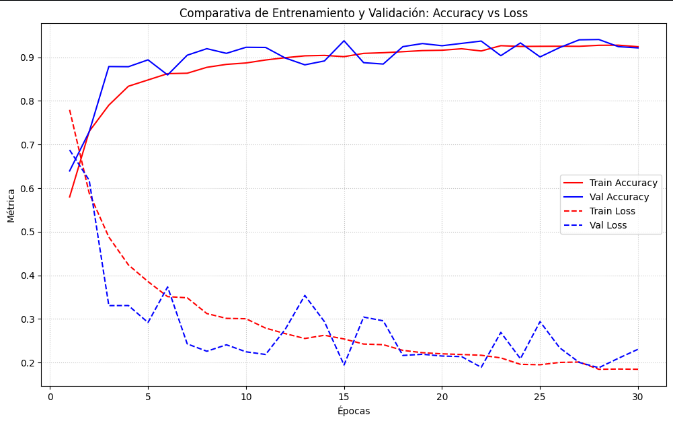

MLP

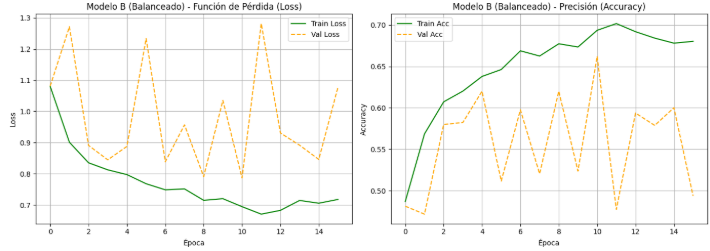

Las curvas de aprendizaje demuestran que la CNN generaliza de manera excelente: sus métricas de entrenamiento y validación son estables, convergen simultáneamente y superan el 90% de exactitud sin mostrar sobreajuste. Por el contrario, el modelo MLP es sumamente inestable; aunque mejora durante el entrenamiento, sus métricas de validación sufren oscilaciones violentas y erráticas en todas las épocas, demostrando su incapacidad para evaluar datos nuevos de forma consistente.

CNN

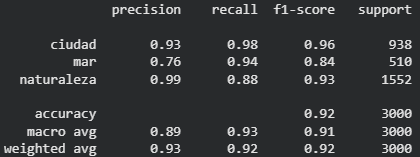

MLP

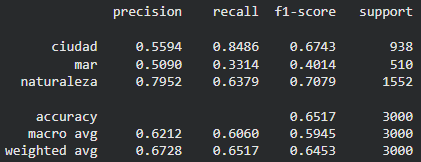

La CNN supera contundentemente al MLP con una exactitud global del 92% frente a un deficiente 65.17%. Al analizar por clases, la CNN logra clasificar "ciudad" y "naturaleza" con métricas sobresalientes (F1-scores por encima de 0.92), mientras que el MLP sufre de abundantes falsos positivos en "ciudad" (55.94% de precisión) y omite casi el 40% de las imágenes reales de "naturaleza" (63.79% de recall). La debilidad más crítica del MLP se evidencia en la clase "mar", donde apenas detecta el 33.14% de los casos, a diferencia de la CNN que encuentra el 94%. Estos datos confirman que la CNN es significativamente superior al procesar imágenes preservando su estructura espacial.

CNN

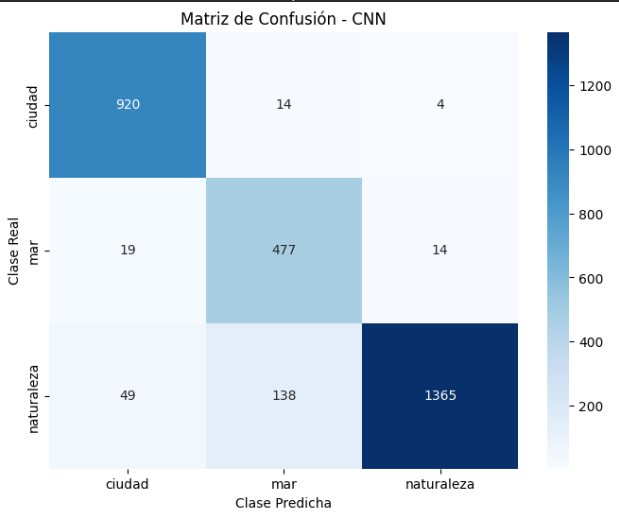

MLP

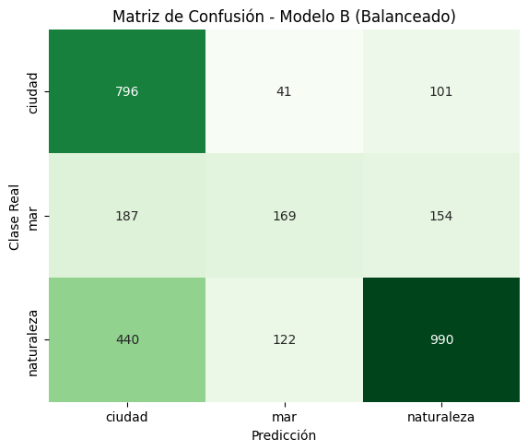

Aunque la clase "mar" sigue presentando el rendimiento más bajo, existe una diferencia clave en el patrón de errores. En el modelo MLP, la mayor parte de los falsos negativos en la clase "naturaleza" ocurre porque el modelo las clasifica erróneamente como "ciudad". En contraste, la CNN tenía mayor tendencia a confundir las imágenes de naturaleza prediciéndolas como "mar".

El entrenamiento de la CNN tardó 35 minutos frente a los 30 segundos del MLP, una diferencia que se justifica por los resultados obtenidos:

Generalización: La CNN aprende patrones estables y generaliza de forma excelente sobre datos nuevos. El MLP es errático y sufre de alta inestabilidad en validación.

Ventajas y Desventajas CNN: Su principal ventaja es que preserva la estructura espacial (2D) logrando una alta precisión visual. Su desventaja es el elevado costo computacional y tiempo de procesamiento.

Ventajas y Desventajas MLP: Su mayor ventaja es la extrema rapidez y simplicidad de cálculo. Su desventaja crítica es que requiere aplanar la imagen (perdiendo su geometría) y genera demasiadas conexiones, haciéndolo ineficiente e impreciso para visión artificial.

# 7. Prediccion de 1 foto

1. Guarda y carga el modelo

In [ ]:
import tensorflow as tf

# Guardar modelo completo (arquitectura, pesos, estado del optimizador)
modelo_cnn.save('modelo_final.keras')

# Cargar modelo desde el archivo
modelo_cargado = tf.keras.models.load_model('modelo_final.keras')

2. Cargar imagen nueva (desde PC en Colab) y Predecir

In [ ]:
from google.colab import files
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt

# 1. Subir archivo desde tu PC
print("Sube una imagen:")
uploaded = files.upload()
ruta_img_nueva = list(uploaded.keys())[0]

# 2. Preprocesar exactamente igual que en el entrenamiento
img = image.load_img(ruta_img_nueva, target_size=(150, 150))
img_tensor = image.img_to_array(img) / 255.0
img_tensor = np.expand_dims(img_tensor, axis=0)

# 3. Predicción
prediccion = modelo_cargado.predict(img_tensor)
clase_idx = np.argmax(prediccion[0])
confianza = np.max(prediccion[0]) * 100

print(f"\nPredicción: {nombres_clases[clase_idx]} (Confianza: {confianza:.2f}%)")

Sube una imagen:


Saving 995.jpg to 995.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 844ms/step

Predicción: naturaleza (Confianza: 99.94%)


# Conclusiones
Diferencias y Ventajas: A diferencia del MLP que aplana la imagen y destruye su geometría, la CNN procesa en 2D preservando la estructura espacial. Esto le permite reconocer patrones sin importar su ubicación, logrando un 92% de exactitud y una generalización estable, muy superior al 65% inestable del MLP.

Limitaciones: El mayor inconveniente de la CNN es su alto tiempo de procesamiento (35 min frente a 30 seg). Además, debido al desbalance de datos original, al modelo le cuesta distinguir la clase minoritaria ("mar"), generando falsos positivos con "naturaleza".

Mejoras futuras: Para solucionar estos problemas, se sugiere aplicar Data Augmentation específico para esa clase. Adicionalmente, el uso de Regularización L2 o Early Stopping ayudaría a optimizar el entrenamiento y evitar cualquier riesgo de sobreajuste.

# Registro experimentacion

1. 0.85 acuraccy, las demas metricas similar, loss más o menos 0.4, 6 clases, confunde mucho entre montañas, bosques y glaciares, tambien entre calles y edificios

2. Segun el problema de la evaluacion anterior, las 6 clases se combinaron en 3, esto redujo las confusiones del modelo, elevando la precisión global al 92%. Los F1-scores destacaron en ciudad (0.96) y naturaleza (0.92), reduciendo el mayor error restante a solo 154 imágenes de naturaleza confundidas con mar (61.8% de los errores con un 8.3% de errores).